# CelebA Dataset EDA

Exploratory analysis of CelebA landmarks and attributes.

## Goals:
1. Load and join landmarks + attributes
2. Analyze attribute popularity
3. Analyze head tilt distribution
4. Identify filtering thresholds

In [2]:
import sys, subprocess
sys.path.insert(0, subprocess.check_output(['git', 'rev-parse', '--show-toplevel']).decode().strip())

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from utils import celeba_data_utils as cu
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)
%matplotlib inline

## Load Data

In [6]:
attributes = cu.load_attributes('../data/celeba_dataset/metadata/list_attr_celeba.csv')
landmarks = cu.load_landmarks('../data/celeba_dataset/metadata/list_landmarks_align_celeba.csv')
landmarks_features = cu.get_landmark_features(landmarks)

# Join on image_id
df = pd.merge(attributes, landmarks_features, on='image_id', how='inner')

# Get column lists
attr_cols = [col for col in attributes.columns if col != 'image_id']

print(f"Total samples: {len(df):,}")
print(f"Attributes: {len(attr_cols)}")
print(f"Columns: {len(df.columns)}")

Total samples: 202,599
Attributes: 40
Columns: 62


## Head Tilt Distribution

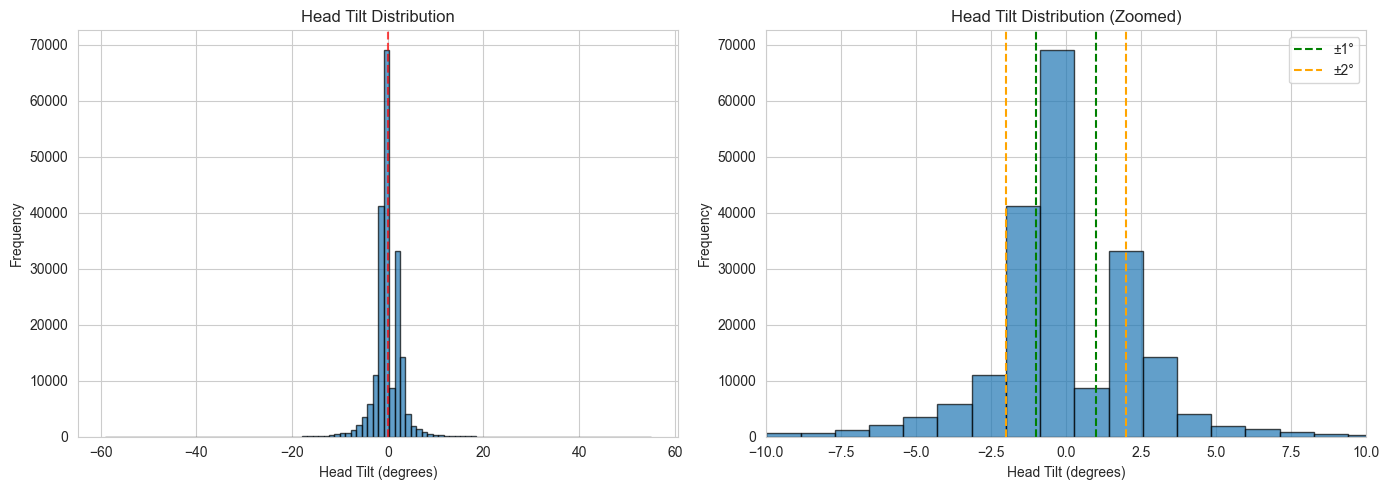


Head Tilt Statistics:
  Mean: -0.065°
  Std:  2.808°
  Min:  -59.036°
  Max:  55.008°


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Full distribution
axes[0].hist(df['head_tilt'], bins=100, edgecolor='black', alpha=0.7)
axes[0].axvline(x=0, color='red', linestyle='--', alpha=0.7)
axes[0].set_xlabel('Head Tilt (degrees)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Head Tilt Distribution')
axes[0].grid(True)

# Zoomed around zero
axes[1].hist(df['head_tilt'], bins=100, edgecolor='black', alpha=0.7)
axes[1].axvline(x=-1, color='green', linestyle='--', label='±1°')
axes[1].axvline(x=1, color='green', linestyle='--')
axes[1].axvline(x=-2, color='orange', linestyle='--', label='±2°')
axes[1].axvline(x=2, color='orange', linestyle='--')
axes[1].set_xlim(-10, 10)
axes[1].set_xlabel('Head Tilt (degrees)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Head Tilt Distribution (Zoomed)')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"\nHead Tilt Statistics:")
print(f"  Mean: {df['head_tilt'].mean():.3f}°")
print(f"  Std:  {df['head_tilt'].std():.3f}°")
print(f"  Min:  {df['head_tilt'].min():.3f}°")
print(f"  Max:  {df['head_tilt'].max():.3f}°")

In [8]:
# Count samples at different tolerances
tolerances = [0.5, 1.0, 2.0, 3.0, 5.0]
print("Samples by head tilt tolerance:")
for tol in tolerances:
    count = (df['head_tilt'].abs() <= tol).sum()
    pct = count / len(df) * 100
    print(f"  |tilt| <= {tol}°: {count:,} ({pct:.1f}%)")

Samples by head tilt tolerance:
  |tilt| <= 0.5°: 69,070 (34.1%)
  |tilt| <= 1.0°: 69,071 (34.1%)
  |tilt| <= 2.0°: 151,793 (74.9%)
  |tilt| <= 3.0°: 162,392 (80.2%)
  |tilt| <= 5.0°: 190,458 (94.0%)


## Other Derived Features

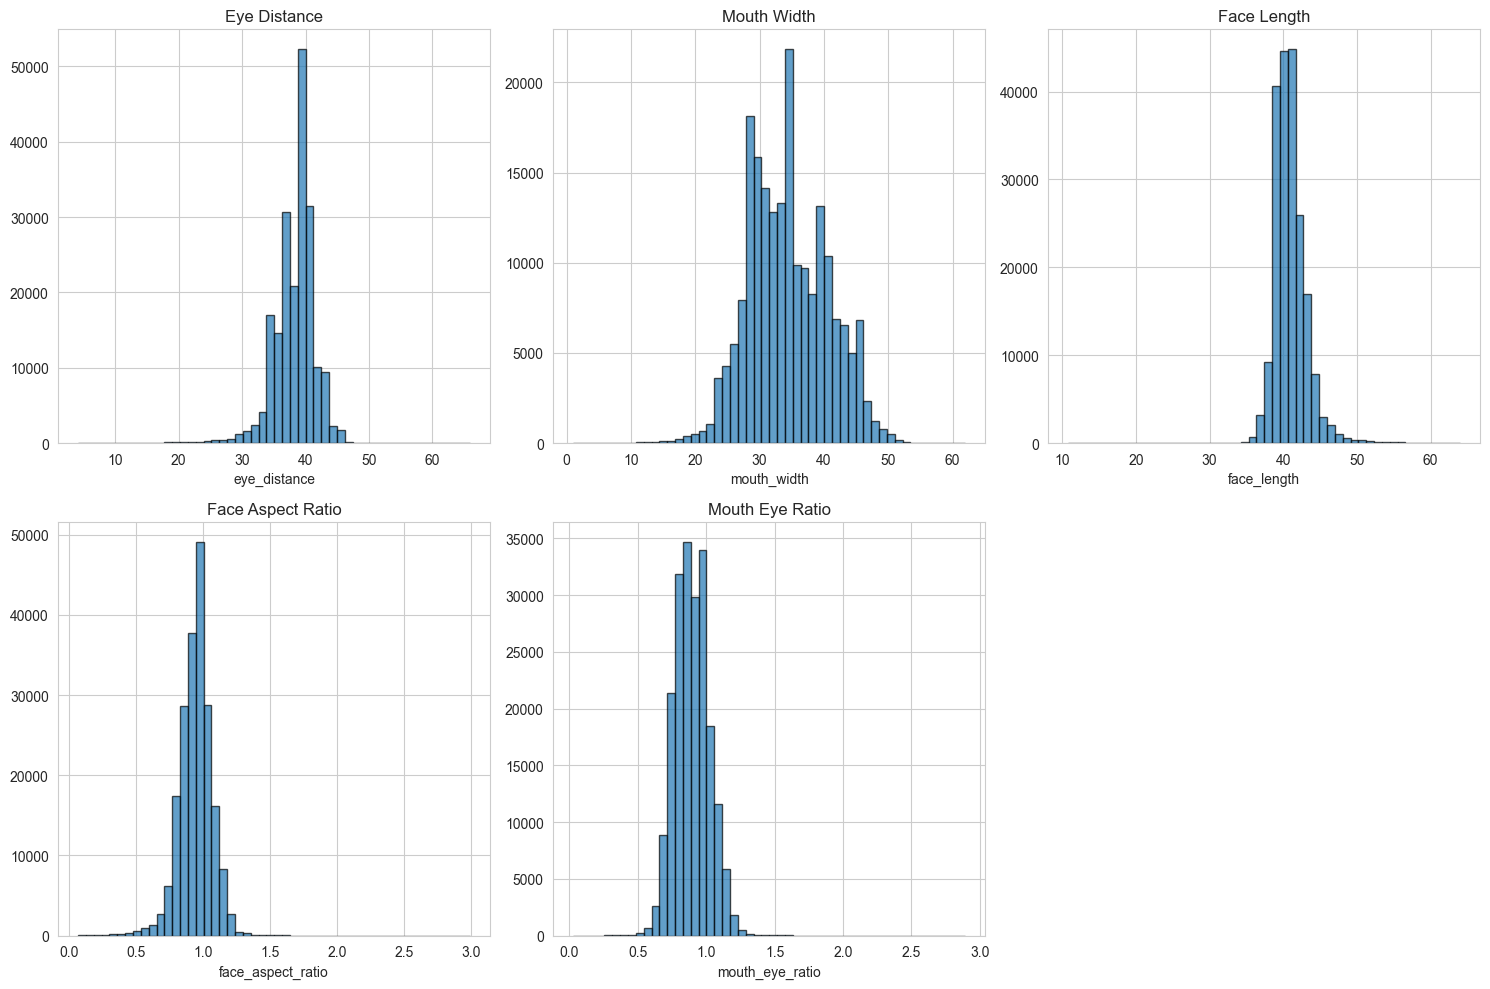

In [9]:
derived_features = ['eye_distance', 'mouth_width', 'face_length',
                    'face_aspect_ratio', 'mouth_eye_ratio']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for idx, feat in enumerate(derived_features):
    axes[idx].hist(df[feat], bins=50, edgecolor='black', alpha=0.7)
    axes[idx].set_title(feat.replace('_', ' ').title())
    axes[idx].set_xlabel(feat)
    axes[idx].grid(True)

# Remove empty subplot
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

## Attribute Popularity

In [10]:
popularity = cu.compute_attribute_popularity(df, attr_cols)
print(popularity.to_string())

              attribute     count  percentage
0              No_Beard  169158.0   83.493996
1                 Young  156734.0   77.361685
2            Attractive  103833.0   51.250500
3   Mouth_Slightly_Open   97942.0   48.342786
4               Smiling   97669.0   48.208037
5      Wearing_Lipstick   95715.0   47.243570
6       High_Cheekbones   92189.0   45.503186
7                  Male   84434.0   41.675428
8          Heavy_Makeup   78390.0   38.692195
9             Wavy_Hair   64744.0   31.956722
10            Oval_Face   57567.0   28.414257
11          Pointy_Nose   56210.0   27.744461
12      Arched_Eyebrows   54090.0   26.698059
13             Big_Lips   48785.0   24.079586
14           Black_Hair   48472.0   23.925093
15             Big_Nose   47516.0   23.453225
16        Straight_Hair   42222.0   20.840182
17           Brown_Hair   41572.0   20.519351
18      Bags_Under_Eyes   41446.0   20.457159
19     Wearing_Earrings   38276.0   18.892492
20                Bangs   30709.0 

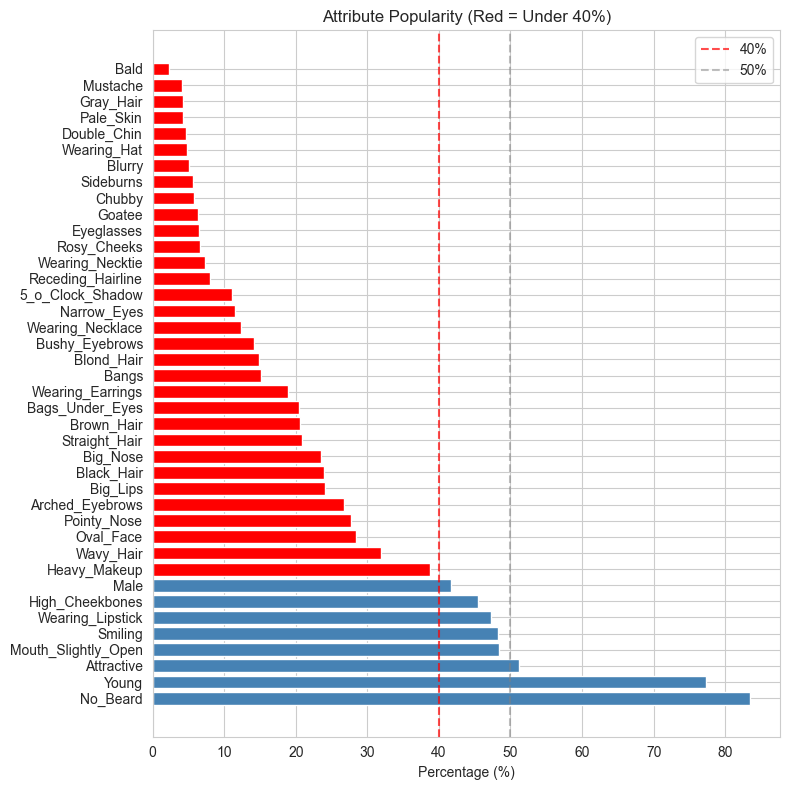


Attributes under 40%: 32
        attribute  percentage
     Heavy_Makeup   38.692195
        Wavy_Hair   31.956722
        Oval_Face   28.414257
      Pointy_Nose   27.744461
  Arched_Eyebrows   26.698059
         Big_Lips   24.079586
       Black_Hair   23.925093
         Big_Nose   23.453225
    Straight_Hair   20.840182
       Brown_Hair   20.519351
  Bags_Under_Eyes   20.457159
 Wearing_Earrings   18.892492
            Bangs   15.157528
       Blond_Hair   14.799185
   Bushy_Eyebrows   14.216753
 Wearing_Necklace   12.296704
      Narrow_Eyes   11.514864
 5_o_Clock_Shadow   11.113579
Receding_Hairline    7.977828
  Wearing_Necktie    7.271507
      Rosy_Cheeks    6.572096
       Eyeglasses    6.511878
           Goatee    6.276438
           Chubby    5.756692
        Sideburns    5.651064
           Blurry    5.089857
      Wearing_Hat    4.846026
      Double_Chin    4.668829
        Pale_Skin    4.294690
        Gray_Hair    4.194986
         Mustache    4.154512
             B

In [11]:
# Visualize
plt.figure(figsize=(8, 8))
colors = ['red' if p < 40 else 'steelblue' for p in popularity['percentage']]
plt.barh(range(len(popularity)), popularity['percentage'], color=colors)
plt.yticks(range(len(popularity)), popularity['attribute'])
plt.xlabel('Percentage (%)')
plt.title('Attribute Popularity (Red = Under 40%)')
plt.axvline(x=40, color='red', linestyle='--', alpha=0.7, label='40%')
plt.axvline(x=50, color='gray', linestyle='--', alpha=0.5, label='50%')
plt.legend()
plt.tight_layout()
plt.show()

# Summary
under_40 = popularity[popularity['percentage'] < 40]
print(f"\nAttributes under 40%: {len(under_40)}")
print(under_40[['attribute', 'percentage']].to_string(index=False))

## Filter Dataset

In [17]:
# Filter parameters
POPULARITY_THRESHOLD = 40.0  # Remove samples with attributes below this %
HEAD_TILT_TOLERANCE = 1.0    # Keep samples with |head_tilt| <= this (degrees)
FACE_ASPECT_THRESHOLD = 0.9

filtered_df, stats = cu.filter_dataset(
    df,
    attr_cols,
    popularity_threshold=POPULARITY_THRESHOLD,
    head_tilt_tolerance=HEAD_TILT_TOLERANCE, 
    face_aspect_ratio_min=FACE_ASPECT_THRESHOLD
)

print(f"\nUnpopular attributes removed ({len(stats['unpopular_attributes'])}):")
for attr in stats['unpopular_attributes']:
    print(f"  - {attr}")


Unpopular attributes removed (32):
  - Heavy_Makeup
  - Wavy_Hair
  - Oval_Face
  - Pointy_Nose
  - Arched_Eyebrows
  - Big_Lips
  - Black_Hair
  - Big_Nose
  - Straight_Hair
  - Brown_Hair
  - Bags_Under_Eyes
  - Wearing_Earrings
  - Bangs
  - Blond_Hair
  - Bushy_Eyebrows
  - Wearing_Necklace
  - Narrow_Eyes
  - 5_o_Clock_Shadow
  - Receding_Hairline
  - Wearing_Necktie
  - Rosy_Cheeks
  - Eyeglasses
  - Goatee
  - Chubby
  - Sideburns
  - Blurry
  - Wearing_Hat
  - Double_Chin
  - Pale_Skin
  - Gray_Hair
  - Mustache
  - Bald


In [18]:
# Check attribute popularity after filtering
remaining_attr_cols = [col for col in attr_cols if col not in stats['unpopular_attributes']]
pop_after = cu.compute_attribute_popularity(filtered_df, remaining_attr_cols)
under_threshold = pop_after[pop_after['percentage'] < POPULARITY_THRESHOLD]

print(f"Remaining attribute columns: {len(remaining_attr_cols)}")
print(f"Dropped columns: {len(stats['unpopular_attributes'])}")
print(f"\nAttributes still under {POPULARITY_THRESHOLD}%: {len(under_threshold)}")
if len(under_threshold) > 0:
    print(under_threshold[['attribute', 'percentage']].to_string(index=False))

Remaining attribute columns: 8
Dropped columns: 32

Attributes still under 40.0%: 2
       attribute  percentage
 High_Cheekbones   34.862385
Wearing_Lipstick   13.302752


## Attribute Correlations

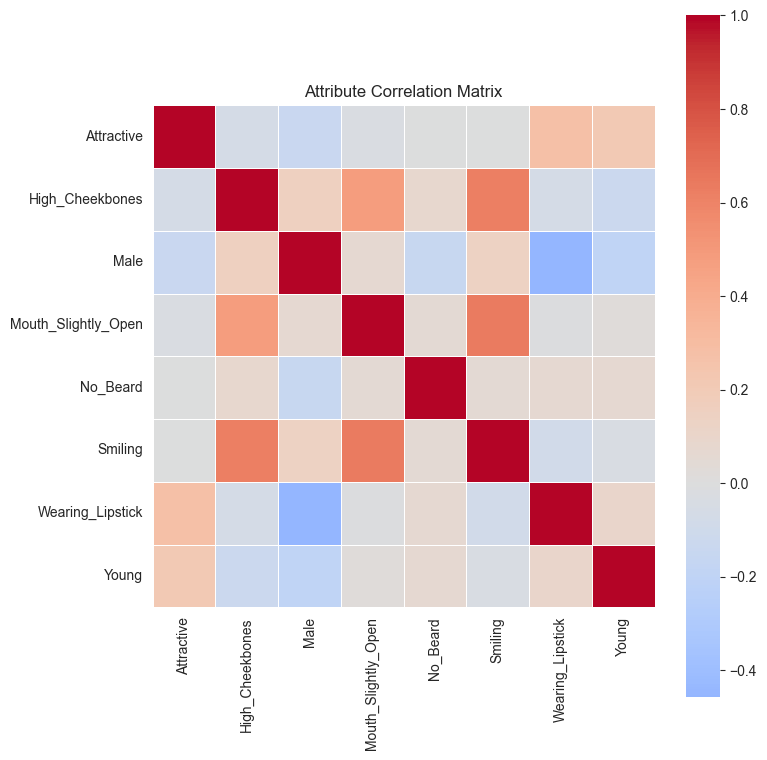

In [19]:
# Correlation matrix
corr = filtered_df[remaining_attr_cols].corr()

plt.figure(figsize=(8, 8))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title('Attribute Correlation Matrix')
plt.tight_layout()
plt.show()

In [20]:
# Top correlations
corr_pairs = []
for i in range(len(remaining_attr_cols)):
    for j in range(i+1, len(remaining_attr_cols)):
        corr_pairs.append({
            'attr1': remaining_attr_cols[i],
            'attr2': remaining_attr_cols[j],
            'correlation': corr.iloc[i, j]
        })

corr_df = pd.DataFrame(corr_pairs).sort_values('correlation', ascending=False)

print("Top 10 Positive Correlations:")
print(corr_df.head(10).to_string(index=False))
print("\nTop 10 Negative Correlations:")
print(corr_df.tail(10).to_string(index=False))

Top 10 Positive Correlations:
              attr1               attr2  correlation
Mouth_Slightly_Open             Smiling     0.633847
    High_Cheekbones             Smiling     0.622270
    High_Cheekbones Mouth_Slightly_Open     0.478360
         Attractive    Wearing_Lipstick     0.275102
         Attractive               Young     0.214439
    High_Cheekbones                Male     0.157203
               Male             Smiling     0.138606
   Wearing_Lipstick               Young     0.097721
    High_Cheekbones            No_Beard     0.078648
           No_Beard    Wearing_Lipstick     0.071347

Top 10 Negative Correlations:
          attr1               attr2  correlation
     Attractive Mouth_Slightly_Open    -0.026269
        Smiling               Young    -0.031103
High_Cheekbones    Wearing_Lipstick    -0.059810
     Attractive     High_Cheekbones    -0.066009
        Smiling    Wearing_Lipstick    -0.088572
High_Cheekbones               Young    -0.125812
     Attracti

## Save New CSV

In [21]:
output_path = '../data/celeba_dataset/celeba_filtered.csv'
filtered_df.to_csv(output_path, index=False)
print(f"Saved to {output_path}")
print(f"Shape: {filtered_df.shape}")

Saved to ../data/celeba_dataset/celeba_filtered.csv
Shape: (218, 30)
